# 08 MCAP assembly

Writes version 1 of the MCAP files (three video channels and the metadata record) for the four episodes.

## 1. Setup

Loads the config, the reports and the per-episode files and checks that everything is on disk.

In [1]:
FORCE = False
DECODE_CHECK = False

# set these only if the key guess printed below is wrong
TS_KEY = None
AU_KEYS = {}

import sys, os, json, time, hashlib, platform, heapq, re, shutil, subprocess, zipfile, inspect
import datetime as dt
from contextlib import ExitStack
from importlib import metadata as imd
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from tqdm import tqdm
import av

try:
    import mcap
    from mcap.reader import make_reader
    from mcap.writer import CompressionType, Writer as McapWriter
    from mcap_protobuf.writer import Writer
    from foxglove_schemas_protobuf.CompressedVideo_pb2 import CompressedVideo
    import google.protobuf
except Exception as e:
    print("import problem:", repr(e))

NOTEBOOK_NAME = "08_mcap_assembly.ipynb"
CAMS = [("head", "cam_high"), ("left", "cam_left_wrist"), ("right", "cam_right_wrist")]
CAM_NAMES = [c for _, c in CAMS]
CAM_RANK = {c: i for i, c in enumerate(CAM_NAMES)}
FRAME_NS = round(1e9 / 30)
RUN_START = dt.datetime.now(dt.timezone.utc)

# project folders
ROOT = Path.cwd().parent
CONFIG_PATH = ROOT / "configs" / "config.yaml"
if not CONFIG_PATH.exists():
    raise RuntimeError(f"configs/config.yaml not found in {ROOT}. open this notebook from the notebooks folder of the project.")
REPORTS = ROOT / "reports"
EPISODES = ROOT / "episodes"
MCAP_DIR = ROOT / "mcap"
REPORTS.mkdir(exist_ok=True)
MCAP_DIR.mkdir(exist_ok=True)


# small helpers
def ver(name):
    try:
        return imd.version(name)
    except Exception:
        return "unknown"


def load_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()


def jdefault(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    return str(o)


def iso_to_us(s):
    d = dt.datetime.fromisoformat(s.replace("Z", "+00:00"))
    return (d - dt.datetime(1970, 1, 1, tzinfo=dt.timezone.utc)) // dt.timedelta(microseconds=1)


def iso_to_ns(s):
    return iso_to_us(s) * 1000


def pick_key(keys, exact, subs=(), skip=()):
    low = {k.lower(): k for k in keys}
    for n in exact:
        if n in low:
            return low[n]
    for s in subs:
        for k in keys:
            if s in k.lower() and not any(x in k.lower() for x in skip):
                return k
    return None


def nal_types(data):
    return sorted({data[m.end()] & 31 for m in re.finditer(rb"\x00\x00\x01", data) if m.end() < len(data)})


# reports
try:
    s06 = load_json(REPORTS / "06_summary.json")
    anchor = load_json(REPORTS / "06_anchor_estimate.json")
    s05 = load_json(REPORTS / "05_summary.json")
    episode_ids = list(s06["episode_ids"])
except Exception as e:
    print("report problem:", repr(e))
    s06, anchor, s05, episode_ids = {}, {}, {}, []

print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__)
print("mcap", ver("mcap"), "| mcap-protobuf-support", ver("mcap-protobuf-support"),
      "| foxglove-schemas-protobuf", ver("foxglove-schemas-protobuf"), "| protobuf", ver("protobuf"))
with open(CONFIG_PATH, encoding="utf-8") as f:
    config = yaml.safe_load(f)
print("config loaded, top level keys:", list(config)[:8] if isinstance(config, dict) else type(config).__name__)
print("episodes:", episode_ids)

# file paths per episode
files = {}
missing = []
for ep in episode_ids:
    d = EPISODES / ep
    files[ep] = {"draft": d / "episode_metadata_draft.json",
                 "strings": d / "episode_metadata_mcap_strings.json",
                 "manifest": d / "video" / "video_manifest.json"}
    for dev, cam in CAMS:
        files[ep][("frames", cam)] = d / f"frames_{dev}.npz"
        files[ep][("h264", cam)] = d / "video" / f"{cam}.h264"
        files[ep][("au", cam)] = d / "video" / f"{cam}_au.npz"
    for key, p in files[ep].items():
        if not p.exists():
            missing.append(f"{ep}: {key} ({p.name})")
print("files checked:", sum(len(v) for v in files.values()), "| missing:", len(missing))
for m in missing[:10]:
    print("  missing", m)


def load_npz(path):
    with np.load(path, allow_pickle=False) as z:
        return {k: z[k] for k in z.files}


def read_au(z, h264_size):
    ko = AU_KEYS.get("offsets") or pick_key(list(z), ["offsets", "offset", "au_offsets", "au_offset", "byte_offsets", "byte_offset", "starts", "start"], ["offset", "start"])
    ks = AU_KEYS.get("sizes") or pick_key(list(z), ["sizes", "size", "au_sizes", "au_size", "lengths", "length", "byte_sizes", "nbytes"], ["size", "len", "nbytes"])
    kf = AU_KEYS.get("frame_index") or pick_key(list(z), ["frame_index", "frame_idx", "frame_indices", "frame", "index", "frame_id"], ["frame", "idx", "index"], skip=["key", "idr"])
    if ko is None:
        raise KeyError("no offset key found, set AU_KEYS")
    off = z[ko].astype(np.int64).ravel()
    size = z[ks].astype(np.int64).ravel() if ks else np.diff(np.append(off, h264_size))
    idx = z[kf].astype(np.int64).ravel() if kf else np.arange(len(off))
    if len(idx) != len(off):
        idx = np.arange(len(off))
    return {"offsets": off, "sizes": size, "frame_index": idx, "keys": (ko, ks, kf)}


drafts, strings_meta, manifests = {}, {}, {}
frames_ts, au = {}, {}
printed = {"frames": False, "au": False, "manifest": False}
ts_key = None
frame_rows = []

for ep in episode_ids:
    frames_ts[ep], au[ep] = {}, {}
    try:
        drafts[ep] = load_json(files[ep]["draft"])
        strings_meta[ep] = load_json(files[ep]["strings"])
        manifests[ep] = load_json(files[ep]["manifest"])
        if not printed["manifest"]:
            print("video_manifest keys:", list(manifests[ep])[:10])
            printed["manifest"] = True
    except Exception as e:
        print(f"{ep}: json problem: {repr(e)}")
    for dev, cam in CAMS:
        row = {"episode_id": ep, "camera": cam, "frames": None, "access_units": None, "h264_bytes": None, "covers_file": None}
        try:
            z = load_npz(files[ep][("frames", cam)])
            if not printed["frames"]:
                print("frames npz keys:", {k: (v.dtype.name, v.shape) for k, v in z.items()})
                printed["frames"] = True
            key = TS_KEY or pick_key(list(z), ["t_us", "ts_us", "timestamp_us", "timestamps_us", "t_session_us", "session_t_us", "time_us", "t"], ["t_us", "timestamp", "_us", "time"])
            if key is None:
                raise KeyError("no timestamp key found, set TS_KEY")
            ts = np.asarray(z[key]).ravel()
            if ts.dtype.kind == "f":
                ts = np.rint(ts)
            frames_ts[ep][cam] = ts.astype(np.int64)
            ts_key = key
            row["frames"] = len(ts)
        except Exception as e:
            print(f"{ep} {cam}: frames problem: {repr(e)}")
        try:
            h264_size = files[ep][("h264", cam)].stat().st_size
            za = load_npz(files[ep][("au", cam)])
            if not printed["au"]:
                print("au npz keys:", {k: (v.dtype.name, v.shape) for k, v in za.items()})
                printed["au"] = True
            a = read_au(za, h264_size)
            au[ep][cam] = a
            off, size = a["offsets"], a["sizes"]
            row["access_units"] = len(off)
            row["h264_bytes"] = h264_size
            row["covers_file"] = bool(len(off) > 0 and off[0] == 0 and np.all(off[1:] == off[:-1] + size[:-1]) and off[-1] + size[-1] == h264_size)
        except Exception as e:
            print(f"{ep} {cam}: access unit problem: {repr(e)}")
        frame_rows.append(row)

print("timestamp key used:", ts_key)
if au and any(au[e] for e in au):
    first_ep = next(e for e in au if au[e])
    print("access unit keys used (offsets, sizes, frame index):", next(iter(au[first_ep].values()))["keys"])
print(pd.DataFrame(frame_rows).to_string(index=False))

python 3.13.13 | numpy 2.5.4 | pandas 3.0.6
mcap 1.5.0 | mcap-protobuf-support 0.5.4 | foxglove-schemas-protobuf 0.4.0 | protobuf 7.36.2
config loaded, top level keys: ['source_root', 'directories', 'devices', 'nominal_fps', 'chunk_seconds_hypothesis', 'thresholds', 'time', 'identity']
episodes: ['vendorX_2026-10-11_op01_000001', 'vendorX_2026-10-11_op01_000002', 'vendorX_2026-10-11_op01_000003', 'vendorX_2026-10-11_op01_000004']
files checked: 48 | missing: 0
video_manifest keys: ['episode_id', 'fps', 'resolution', 'codec', 'crf', 'preset', 'ffmpeg_version', 'colour', 'colour_conversion', 'mp4_copy']
frames npz keys: {'ts_session_us': ('int64', (21240,)), 'flags': ('uint8', (21240,)), 'source_clip': ('int64', (21240,)), 'local_i': ('int64', (21240,)), 'global_n': ('int64', (21240,)), 'acc': ('float64', (21240, 3)), 'gyro': ('float64', (21240, 3)), 'source_clips': ('str416', (5,))}
au npz keys: {'offsets': ('int64', (21240,)), 'sizes': ('int64', (21240,)), 'is_key': ('bool', (21240,)),

## 2. Timestamps

Builds the UTC timestamps in nanoseconds for every frame and checks them against the number of access units.

In [2]:
utc_ns = {}
ts_rows = []
mode = "raw session clock"


def to_utc_us(t, how):
    if how == "raw session clock":
        return zero_utc_us + (t - zero_us)
    if how == "relative to zero":
        return zero_utc_us + t
    return t


# mapping check with the first head frame of episode 1
try:
    zero_utc_us = int(anchor["session_zero_utc_us"])
    zero_us = int(s05["session_zero_us"])
    if "session_zero_utc" in anchor:
        print("anchor iso vs anchor us (ms):", (iso_to_us(anchor["session_zero_utc"]) - zero_utc_us) / 1000)
    ep1 = episode_ids[0]
    start_us = iso_to_us(drafts[ep1]["capture_start_iso"])
    t_first = int(frames_ts[ep1]["cam_high"][0])
    options = {"raw session clock": zero_utc_us + (t_first - zero_us),
               "relative to zero": zero_utc_us + t_first,
               "already utc": t_first}
    found = None
    for name, val in options.items():
        diff_ms = (val - start_us) / 1000
        print(f"{name:20s} first head frame minus capture_start_iso: {diff_ms:12.3f} ms")
        if found is None and abs(diff_ms) <= 1:
            found = name
    if found is None:
        print("no formula agrees within 1 ms, using the raw session clock formula anyway")
    else:
        mode = found
    print("utc mapping used:", mode)
except Exception as e:
    print("mapping check problem:", repr(e))

for ep in episode_ids:
    utc_ns[ep] = {}
    for dev, cam in CAMS:
        try:
            t = frames_ts[ep][cam]
            utc_ns[ep][cam] = to_utc_us(t, mode) * 1000
            d = np.diff(utc_ns[ep][cam])
            n_au = len(au[ep][cam]["offsets"])
            ts_rows.append({"episode_id": ep, "camera": cam, "timestamps": len(t), "access_units": n_au,
                            "length_ok": len(t) == n_au, "equal_values": int((d == 0).sum()), "decreasing": int((d < 0).sum())})
        except Exception as e:
            print(f"{ep} {cam}: timestamp problem: {repr(e)}")

ts_check = pd.DataFrame(ts_rows)
print(ts_check.to_string(index=False))

anchor iso vs anchor us (ms): -0.044
raw session clock    first head frame minus capture_start_iso:    -7782.651 ms
relative to zero     first head frame minus capture_start_iso:        0.262 ms
already utc          first head frame minus capture_start_iso: -1791729628653.782 ms
utc mapping used: relative to zero
                    episode_id          camera  timestamps  access_units  length_ok  equal_values  decreasing
vendorX_2026-10-11_op01_000001        cam_high       21240         21240       True             0           0
vendorX_2026-10-11_op01_000001  cam_left_wrist       21239         21239       True             0           0
vendorX_2026-10-11_op01_000001 cam_right_wrist       21239         21239       True             0           0
vendorX_2026-10-11_op01_000002        cam_high        9390          9390       True             0           0
vendorX_2026-10-11_op01_000002  cam_left_wrist        9390          9390       True             0           0
vendorX_2026-10-11_op01_0

## 3. Metadata

Builds the final metadata dict of each episode from the strings file.

In [3]:
PENDING = ["language_instruction", "spans", "pose_modality", "coverage", "calibration", "hand_pose_topics"]
NULL_KEYS = ["language_instruction", "spans", "pose_modality", "coverage"]
KEEP_KEYS = ["episode_id", "capture_start_iso", "capture_stop_iso", "fps", "duration_sec", "max_timesteps"]


def walk(obj, key=None):
    # yields (key, value) for every nested item
    if isinstance(obj, dict):
        for k, v in obj.items():
            yield k, v
            yield from walk(v, k)
    elif isinstance(obj, list):
        for v in obj:
            yield key, v
            yield from walk(v, key)


def first_line(s):
    return s.strip().split("\n")[0]


def find_ffmpeg_line(m):
    for k, v in walk(m):
        if isinstance(v, str) and v.strip().lower().startswith("ffmpeg version"):
            return first_line(v)
    for k, v in walk(m):
        if "ffmpeg" in str(k).lower() and isinstance(v, str) and v.strip():
            return first_line(v)
    return "not found"


def find_x264(m):
    found = []

    def go(o):
        if isinstance(o, dict):
            for k, v in o.items():
                if "x264" in str(k).lower():
                    if v not in found:
                        found.append(v)
                else:
                    go(v)
        elif isinstance(o, list):
            for v in o:
                go(v)

    go(m)
    if not found:
        for k, v in walk(m):
            if isinstance(v, str) and "x264" in v.lower() and "ffmpeg version" not in v.lower() and v not in found:
                found.append(v)
    if not found:
        return "not found"
    return found[0] if len(found) == 1 else found


final_meta = {}
required_keys = {}

for ep in episode_ids:
    try:
        src = strings_meta[ep]
        meta = dict(src)
        required_keys[ep] = list(src.keys())
        for k in NULL_KEYS:
            meta[k] = "null"
        meta["pending"] = json.dumps(PENDING)
        meta["assembly_stage"] = "v1_video_only"

        # producer info goes into source_provenance
        try:
            prov = json.loads(meta.get("source_provenance", "{}"))
        except Exception:
            print(f"{ep}: source_provenance is not json, starting a new one")
            prov = {}
        if not isinstance(prov, dict):
            prov = {"original": prov}
        prov["producer"] = {
            "notebook": NOTEBOOK_NAME,
            "python": platform.python_version(),
            "mcap": ver("mcap"),
            "mcap_protobuf": ver("mcap-protobuf-support"),
            "foxglove_schemas_protobuf": ver("foxglove-schemas-protobuf"),
            "ffmpeg_version_line": find_ffmpeg_line(manifests[ep]),
            "x264_settings": find_x264(manifests[ep]),
        }
        meta["source_provenance"] = json.dumps(prov)

        # drop hand_pose from the tags
        tags = meta.get("episode_tags")
        if tags is None:
            print(f"{ep}: no episode_tags key in the strings file")
        else:
            try:
                lst = json.loads(tags)
                if not isinstance(lst, list):
                    raise ValueError
                seps = (",", ":") if ", " not in tags else (", ", ": ")
                meta["episode_tags"] = json.dumps([t for t in lst if t != "hand_pose"], separators=seps)
            except ValueError:
                meta["episode_tags"] = ",".join(p for p in re.split(r"\s*,\s*", tags) if p != "hand_pose")
            if "vendor" not in meta["episode_tags"] or "egocentric" not in meta["episode_tags"]:
                print(f"{ep}: vendor or egocentric tag missing in episode_tags")

        # everything must be a string
        fixed = [k for k, v in meta.items() if not isinstance(v, str)]
        for k in fixed:
            meta[k] = json.dumps(meta[k])
        if fixed:
            print(f"{ep}: converted to string:", fixed)

        changed = [k for k in KEEP_KEYS if k in src and meta.get(k) != src[k]]
        if changed:
            print(f"{ep}: protected keys changed (should not happen):", changed)
        final_meta[ep] = meta
    except Exception as e:
        print(f"{ep}: metadata problem: {repr(e)}")

print("metadata built for", len(final_meta), "of", len(episode_ids), "episodes")
if episode_ids and episode_ids[0] in final_meta:
    print(f"metadata of {episode_ids[0]} (values cut at 160 characters):")
    for k, v in final_meta[episode_ids[0]].items():
        print(f"  {k}: {v if len(v) <= 160 else v[:160] + '...'}")

metadata built for 4 of 4 episodes
metadata of vendorX_2026-10-11_op01_000001 (values cut at 160 characters):
  episode_id: vendorX_2026-10-11_op01_000001
  capture_start_iso: 2026-10-11T14:45:00.677Z
  capture_stop_iso: 2026-10-11T14:56:48.690Z
  fps: 30.0
  fps_rational: 30/1
  duration_sec: 708.0
  max_timesteps: 21240
  rig: {"description": "chest-mounted egocentric camera looking down (raw image rotated 180 degrees) + left and right wrist cameras looking at the palms, 1920x1080 at ...
  cameras: {"cam_high": {"role": "egocentric", "resolution": [1920, 1080], "is_pose_source": true}, "cam_left_wrist": {"role": "left_wrist", "resolution": [1920, 1080]}, "...
  user_id: op01
  task_id: 0001
  task_name: wash and chop onion, tomato, ginger and coriander
  language_instruction: null
  spans: null
  pose_modality: null
  coverage: null
  pending: ["language_instruction", "spans", "pose_modality", "coverage", "calibration", "hand_pose_topics"]
  episode_tags: ["vendorX", "egocentric"]
  

## 4. Write MCAP files

Writes one MCAP file per episode with the three camera channels and the metadata record. Existing files with a recorded hash are skipped unless FORCE is on.

In [4]:
write_log = {}


def open_writer(f):
    params = inspect.signature(Writer.__init__).parameters
    name = "compression" if "compression" in params else "chunk_compression"
    return Writer(f, **{name: CompressionType.NONE})


def add_metadata(w, name, data):
    # the mcap_protobuf writer wraps the plain mcap writer
    if hasattr(w, "add_metadata"):
        return w.add_metadata(name, data)
    for v in vars(w).values():
        if isinstance(v, McapWriter):
            return v.add_metadata(name, data)
    raise RuntimeError("cannot reach the metadata call of the writer")


def recorded_sha(ep):
    p = REPORTS / "08_mcap_manifest.csv"
    if not p.exists():
        return None
    m = pd.read_csv(p, dtype=str)
    row = m[m["episode_id"] == ep]
    if len(row) == 0 or pd.isna(row.iloc[0]["sha256"]):
        return None
    return row.iloc[0]["sha256"]


def stream(ep, cam):
    ts = utc_ns[ep][cam]
    for i in range(len(ts)):
        yield (int(ts[i]), CAM_RANK[cam], i)


def write_episode(ep, out):
    tmp = out.with_name(out.name + ".tmp")
    total = sum(len(utc_ns[ep][c]) for c in CAM_NAMES)
    merged = heapq.merge(*[stream(ep, c) for c in CAM_NAMES])
    n = 0
    try:
        with open(tmp, "wb") as f, ExitStack() as stack:
            handles = {c: stack.enter_context(open(files[ep][("h264", c)], "rb")) for c in CAM_NAMES}
            w = open_writer(f)
            add_metadata(w, "episode_metadata", final_meta[ep])
            bar = tqdm(total=total, desc=ep, unit="msg", mininterval=0.5)
            for ns, rank, i in merged:
                cam = CAM_NAMES[rank]
                a = au[ep][cam]
                h = handles[cam]
                h.seek(int(a["offsets"][i]))
                data = h.read(int(a["sizes"][i]))
                if len(data) != int(a["sizes"][i]):
                    raise RuntimeError(f"short read in {cam} at access unit {i}")
                sec, nsec = divmod(ns, 1_000_000_000)
                msg = CompressedVideo()
                msg.timestamp.seconds = sec
                msg.timestamp.nanos = nsec
                msg.frame_id = cam
                msg.format = "h264"
                msg.data = data
                w.write_message(topic=f"/cameras/{cam}", message=msg, log_time=ns, publish_time=ns, sequence=int(a["frame_index"][i]))
                n += 1
                bar.update(1)
            bar.close()
            w.finish()
        os.replace(tmp, out)
    finally:
        if tmp.exists():
            tmp.unlink()
    return n


for ep in episode_ids:
    out = MCAP_DIR / f"{ep}.mcap"
    try:
        if ep not in final_meta or ep not in utc_ns:
            raise RuntimeError("metadata or timestamps missing")
        rec = recorded_sha(ep)
        if out.exists() and rec and not FORCE:
            if sha256_file(out) == rec:
                print(f"{ep}: skipped, file exists and matches the recorded sha256")
                continue
            print(f"{ep}: existing file does not match the recorded sha256, writing again")
        t0 = time.time()
        n = write_episode(ep, out)
        secs = time.time() - t0
        write_log[ep] = {"messages": n, "seconds": secs}
        print(f"{ep}: {n} messages, {out.stat().st_size / 1e6:.1f} MB, {secs:.1f} s")
    except Exception as e:
        print(f"{ep}: write problem: {repr(e)}")

vendorX_2026-10-11_op01_000001: 100%|██████████| 63718/63718 [01:01<00:00, 1030.49msg/s]


vendorX_2026-10-11_op01_000001: 63718 messages, 2066.8 MB, 64.5 s


vendorX_2026-10-11_op01_000002: 100%|██████████| 28170/28170 [00:10<00:00, 2618.95msg/s]


vendorX_2026-10-11_op01_000002: 28170 messages, 851.9 MB, 11.1 s


vendorX_2026-10-11_op01_000003: 100%|██████████| 31229/31229 [00:32<00:00, 951.69msg/s] 


vendorX_2026-10-11_op01_000003: 31229 messages, 976.8 MB, 32.9 s


vendorX_2026-10-11_op01_000004: 100%|██████████| 53998/53998 [00:31<00:00, 1721.89msg/s]


vendorX_2026-10-11_op01_000004: 53998 messages, 1691.5 MB, 32.3 s


## 5. Read back

Reads every file again and checks channels, message counts, time order, the first frames and the video bytes.

In [5]:
scan = {}
log_times = {}
orig_sha = {}
check_rows = []


def scan_mcap(path):
    res = {"channels": [], "stats": {}, "meta": [], "file_dec": 0, "cams": {}}
    with open(path, "rb") as f:
        reader = make_reader(f)
        summary = reader.get_summary()
        if summary is not None:
            for ch in summary.channels.values():
                sch = summary.schemas.get(ch.schema_id)
                res["channels"].append({"topic": ch.topic, "schema": sch.name if sch else "", "encoding": ch.message_encoding})
            st = summary.statistics
            if st is not None:
                names = {cid: ch.topic for cid, ch in summary.channels.items()}
                res["stats"] = {"messages": st.message_count, "channels": st.channel_count, "chunks": st.chunk_count,
                                "per_topic": {names.get(c, str(c)): n for c, n in st.channel_message_counts.items()}}
        for md in reader.iter_metadata():
            res["meta"].append((md.name, dict(md.metadata)))
        prev = None
        for schema, channel, message in reader.iter_messages(log_time_order=False):
            if prev is not None and message.log_time < prev:
                res["file_dec"] += 1
            prev = message.log_time
            cam = channel.topic.split("/")[-1]
            c = res["cams"].setdefault(cam, {"sha": hashlib.sha256(), "times": [], "first": None, "topic": channel.topic, "bad": 0})
            c["times"].append(message.log_time)
            if schema is None or schema.name != "foxglove.CompressedVideo":
                c["bad"] += 1
                continue
            msg = CompressedVideo.FromString(message.data)
            c["sha"].update(msg.data)
            if c["first"] is None:
                c["first"] = {"format": msg.format, "frame_id": msg.frame_id, "nal": nal_types(msg.data)}
    return res


def count_decoded(path, topic):
    # feeds the access units one by one to the h264 decoder
    ctx = av.CodecContext.create("h264", "r")
    n = 0
    with open(path, "rb") as f:
        reader = make_reader(f)
        for schema, channel, message in reader.iter_messages(topics=[topic], log_time_order=False):
            data = CompressedVideo.FromString(message.data).data
            for pkt in ctx.parse(data):
                n += len(ctx.decode(pkt))
    for pkt in ctx.parse(None):
        n += len(ctx.decode(pkt))
    n += len(ctx.decode(None))
    return n


for ep in episode_ids:
    path = MCAP_DIR / f"{ep}.mcap"
    try:
        r = scan_mcap(path)
        r["ok"] = True
    except Exception as e:
        print(f"{ep}: could not read back: {repr(e)}")
        scan[ep] = {"ok": False}
        continue

    recs = [m for n, m in r["meta"] if n == "episode_metadata"]
    rec = recs[0] if recs else None
    r["meta_found"] = rec is not None
    r["meta_strings"] = bool(rec is not None and all(isinstance(k, str) and isinstance(v, str) for k, v in rec.items()))
    r["meta_required"] = int(sum(k in rec for k in required_keys.get(ep, []))) if rec is not None else 0
    r["meta_keys"] = len(rec) if rec is not None else 0
    r["meta_same"] = bool(rec is not None and rec == final_meta.get(ep))
    scan[ep] = r

    st = r["stats"]
    print(f"{ep}: {len(r['channels'])} channels, statistics: {st.get('messages')} messages, {st.get('chunks')} chunks | metadata record found: {r['meta_found']}, keys: {r['meta_keys']}, same as step 3: {r['meta_same']}")

    for cam in CAM_NAMES:
        c = r["cams"].get(cam)
        row = {"episode_id": ep, "camera": cam, "topic": f"/cameras/{cam}", "schema": "", "encoding": "", "messages": 0,
               "expected_frames": len(utc_ns.get(ep, {}).get(cam, [])), "stats_count": None,
               "first_format": "", "first_frame_id": "", "nal_types": "", "idr_sps_pps": False,
               "nondecreasing_channel": False, "nondecreasing_file": r["file_dec"] == 0,
               "sha256_stream": "", "sha256_h264": "", "identical": False, "decoded_frames": None,
               "metadata_found": r["meta_found"], "metadata_all_strings": r["meta_strings"]}
        for ch in r["channels"]:
            if ch["topic"] == row["topic"]:
                row["schema"], row["encoding"] = ch["schema"], ch["encoding"]
        row["stats_count"] = st.get("per_topic", {}).get(row["topic"])
        if c is not None:
            t = np.array(c["times"], dtype=np.int64)
            log_times[(ep, cam)] = t
            row["messages"] = len(t)
            row["nondecreasing_channel"] = bool(np.all(np.diff(t) >= 0))
            if c["first"] is not None:
                fm = c["first"]
                row["first_format"], row["first_frame_id"] = fm["format"], fm["frame_id"]
                row["nal_types"] = ",".join(str(x) for x in fm["nal"])
                row["idr_sps_pps"] = {5, 7, 8} <= set(fm["nal"])
            row["sha256_stream"] = c["sha"].hexdigest()
            try:
                if (ep, cam) not in orig_sha:
                    orig_sha[(ep, cam)] = sha256_file(files[ep][("h264", cam)])
                row["sha256_h264"] = orig_sha[(ep, cam)]
                row["identical"] = row["sha256_stream"] == row["sha256_h264"]
            except Exception as e:
                print(f"{ep} {cam}: could not hash the h264 file: {repr(e)}")
            if DECODE_CHECK:
                try:
                    row["decoded_frames"] = count_decoded(path, row["topic"])
                except Exception as e:
                    print(f"{ep} {cam}: decode problem: {repr(e)}")
        check_rows.append(row)

check_df = pd.DataFrame(check_rows)
check_df.to_csv(REPORTS / "08_mcap_check.csv", index=False)
if len(check_df):
    cols = ["episode_id", "camera", "messages", "expected_frames", "nondecreasing_channel", "idr_sps_pps", "identical"]
    if DECODE_CHECK:
        cols.append("decoded_frames")
    print(check_df[cols].to_string(index=False))

vendorX_2026-10-11_op01_000001: 3 channels, statistics: 63718 messages, 1917 chunks | metadata record found: True, keys: 20, same as step 3: True
vendorX_2026-10-11_op01_000002: 3 channels, statistics: 28170 messages, 789 chunks | metadata record found: True, keys: 20, same as step 3: True
vendorX_2026-10-11_op01_000003: 3 channels, statistics: 31229 messages, 907 chunks | metadata record found: True, keys: 20, same as step 3: True
vendorX_2026-10-11_op01_000004: 3 channels, statistics: 53998 messages, 1568 chunks | metadata record found: True, keys: 20, same as step 3: True
                    episode_id          camera  messages  expected_frames  nondecreasing_channel  idr_sps_pps  identical
vendorX_2026-10-11_op01_000001        cam_high     21240            21240                   True         True       True
vendorX_2026-10-11_op01_000001  cam_left_wrist     21239            21239                   True         True       True
vendorX_2026-10-11_op01_000001 cam_right_wrist     2123

## 6. Time consistency

Compares the first and last message times with the capture times in the metadata and the three cameras with each other.

In [6]:
time_rows = []
for ep in episode_ids:
    try:
        meta = final_meta[ep]
        start_ns = iso_to_ns(meta["capture_start_iso"])
        stop_ns = iso_to_ns(meta["capture_stop_iso"])
        first_high = int(log_times[(ep, "cam_high")][0])
        last_high = int(log_times[(ep, "cam_high")][-1])
        for cam in CAM_NAMES:
            t = log_times[(ep, cam)]
            d = np.diff(t)
            row = {"episode_id": ep, "camera": cam,
                   "first_vs_cam_high_ms": (int(t[0]) - first_high) / 1e6,
                   "last_vs_cam_high_ms": (int(t[-1]) - last_high) / 1e6,
                   "equal_pairs": int((d == 0).sum()),
                   "gaps_50ms_or_more": int((d >= 50_000_000).sum()),
                   "max_gap_ms": float(d.max()) / 1e6 if len(d) else 0.0,
                   "start_vs_metadata_ms": None, "stop_vs_metadata_ms": None}
            if cam == "cam_high":
                row["start_vs_metadata_ms"] = (first_high - start_ns) / 1e6
                row["stop_vs_metadata_ms"] = (last_high + FRAME_NS - stop_ns) / 1e6
            time_rows.append(row)
    except Exception as e:
        print(f"{ep}: time check problem: {repr(e)}")

time_df = pd.DataFrame(time_rows)
time_df.to_csv(REPORTS / "08_time_consistency.csv", index=False)
if len(time_df):
    print(time_df.round(3).to_string(index=False))

                    episode_id          camera  first_vs_cam_high_ms  last_vs_cam_high_ms  equal_pairs  gaps_50ms_or_more  max_gap_ms  start_vs_metadata_ms  stop_vs_metadata_ms
vendorX_2026-10-11_op01_000001        cam_high                 0.000                0.000            0                 10      70.587                 0.262               -0.441
vendorX_2026-10-11_op01_000001  cam_left_wrist                -0.986                0.911            0                 11      69.353                   NaN                  NaN
vendorX_2026-10-11_op01_000001 cam_right_wrist                -0.461               -0.528            0                 11      69.899                   NaN                  NaN
vendorX_2026-10-11_op01_000002        cam_high                 0.000                0.000            0                  4      68.724                 0.043               -0.204
vendorX_2026-10-11_op01_000002  cam_left_wrist                 3.401                3.232            0             

## 7. mcap command line tool

Runs mcap info and mcap doctor on every file if the tool is on the path.

In [7]:
cli_info = {"found": False, "doctor_ok": {}}
exe = shutil.which("mcap")
if exe is None:
    print("mcap command line tool not found on PATH, skipping this step")
else:
    cli_info["found"] = True
    lines = []
    for ep in episode_ids:
        path = MCAP_DIR / f"{ep}.mcap"
        if not path.exists():
            continue
        rc = {}
        for sub in ("info", "doctor"):
            try:
                p = subprocess.run([exe, sub, str(path)], capture_output=True, text=True, encoding="utf-8", errors="replace", timeout=900)
                rc[sub] = p.returncode
                lines.append(f"===== mcap {sub} {path.name} (exit code {p.returncode}) =====")
                lines.append(p.stdout.strip())
                if p.stderr.strip():
                    lines.append(p.stderr.strip())
            except Exception as e:
                rc[sub] = None
                lines.append(f"===== mcap {sub} {path.name} failed: {repr(e)} =====")
        cli_info["doctor_ok"][ep] = rc.get("doctor") == 0
        print(f"{ep}: info exit code {rc.get('info')}, doctor exit code {rc.get('doctor')}")
    (REPORTS / "08_mcap_cli.txt").write_text("\n".join(lines) + "\n", encoding="utf-8")
    print("saved", REPORTS / "08_mcap_cli.txt")

mcap command line tool not found on PATH, skipping this step


## 8. Sizes and manifest

Collects size, hash and duration of every file and saves the manifest.

In [8]:
manifest_rows = []
size_rows = []
for ep in episode_ids:
    p = MCAP_DIR / f"{ep}.mcap"
    try:
        size = p.stat().st_size
        sha = sha256_file(p)
        all_t = np.concatenate([log_times[(ep, c)] for c in CAM_NAMES if (ep, c) in log_times])
        dur = (int(all_t.max()) - int(all_t.min()) + FRAME_NS) / 1e9
        counts = {c: len(log_times[(ep, c)]) for c in CAM_NAMES if (ep, c) in log_times}
        manifest_rows.append({"episode_id": ep, "relative_path": p.relative_to(ROOT).as_posix(), "sha256": sha,
                              "size_bytes": size, "duration_s": round(dur, 3), "frames_cam_high": counts.get("cam_high"),
                              "assembly_stage": final_meta[ep]["assembly_stage"]})
        size_rows.append({"episode_id": ep, "size_bytes": size, "gb": round(size / 1e9, 4),
                          "bytes_per_hour": int(size / (dur / 3600)), "duration_s": round(dur, 2),
                          "meta_duration_sec": final_meta[ep].get("duration_sec"), "messages": counts})
    except Exception as e:
        print(f"{ep}: manifest problem: {repr(e)}")

manifest_df = pd.DataFrame(manifest_rows)
manifest_df.to_csv(REPORTS / "08_mcap_manifest.csv", index=False)
print(pd.DataFrame(size_rows).to_string(index=False))

                    episode_id  size_bytes     gb  bytes_per_hour  duration_s meta_duration_sec                                                               messages
vendorX_2026-10-11_op01_000001  2066836536 2.0668     10509127626      708.01             708.0 {'cam_high': 21240, 'cam_left_wrist': 21239, 'cam_right_wrist': 21239}
vendorX_2026-10-11_op01_000002   851916999 0.8519      9798563364      312.99             313.0    {'cam_high': 9390, 'cam_left_wrist': 9390, 'cam_right_wrist': 9390}
vendorX_2026-10-11_op01_000003   976787925 0.9768     10134493705      346.98             347.0 {'cam_high': 10410, 'cam_left_wrist': 10410, 'cam_right_wrist': 10409}
vendorX_2026-10-11_op01_000004  1691470833 1.6915     10148909786      599.99             600.0 {'cam_high': 18000, 'cam_left_wrist': 17999, 'cam_right_wrist': 17999}


## 9. Message timing figure

Plots the message intervals and the offsets between the cameras for episode 1.

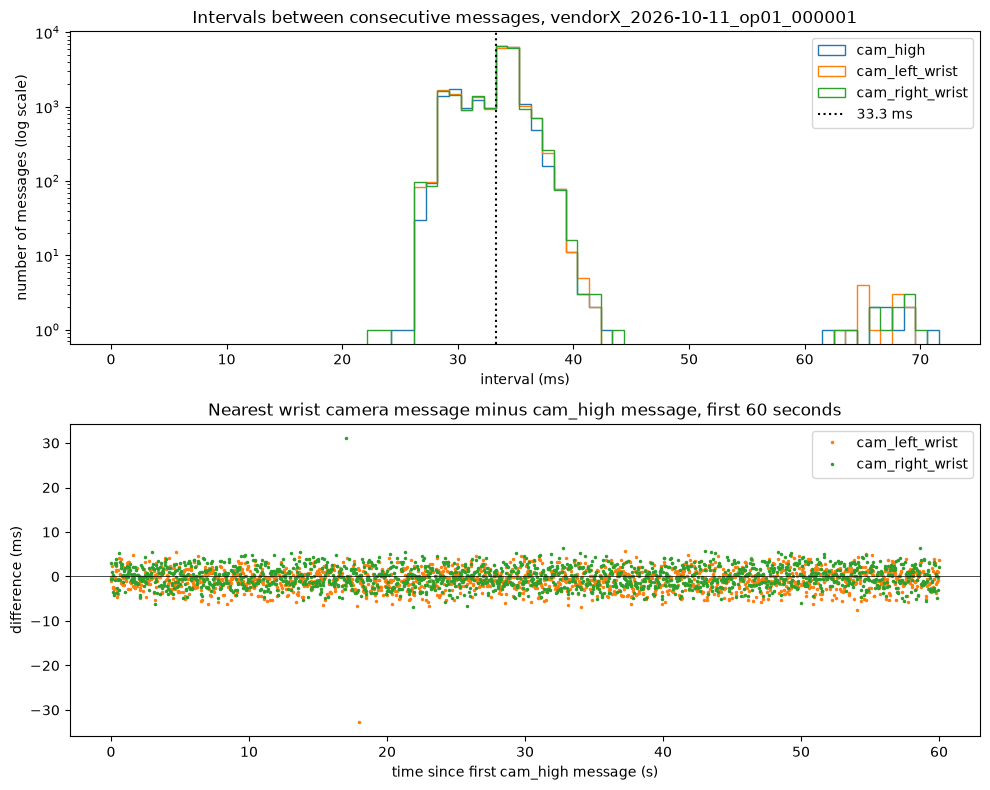

In [9]:
def nearest_diff(ref, other):
    # difference to the nearest message of the other camera, in ns
    idx = np.searchsorted(other, ref)
    lo = np.clip(idx - 1, 0, len(other) - 1)
    hi = np.clip(idx, 0, len(other) - 1)
    dlo = other[lo] - ref
    dhi = other[hi] - ref
    return np.where(np.abs(dlo) <= np.abs(dhi), dlo, dhi)


try:
    ep1 = episode_ids[0]
    t = {c: np.sort(log_times[(ep1, c)]) for c in CAM_NAMES}
    colors = {"cam_high": "tab:blue", "cam_left_wrist": "tab:orange", "cam_right_wrist": "tab:green"}
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

    hi = max(float(np.diff(t[c]).max()) for c in CAM_NAMES) / 1e6
    bins = np.linspace(0, hi + 1, max(int(min(hi + 2, 2000)), 10))
    for c in CAM_NAMES:
        ax1.hist(np.diff(t[c]) / 1e6, bins=bins, histtype="step", label=c, color=colors[c])
    ax1.axvline(1000 / 30, color="k", linestyle=":", label="33.3 ms")
    ax1.set_yscale("log")
    ax1.set_title(f"Intervals between consecutive messages, {ep1}")
    ax1.set_xlabel("interval (ms)")
    ax1.set_ylabel("number of messages (log scale)")
    ax1.legend()

    ref = t["cam_high"]
    sel = ref[ref - ref[0] < 60_000_000_000]
    x = (sel - ref[0]) / 1e9
    for c in ("cam_left_wrist", "cam_right_wrist"):
        ax2.plot(x, nearest_diff(sel, t[c]) / 1e6, ".", markersize=3, label=c, color=colors[c])
    ax2.axhline(0, color="k", linewidth=0.5)
    ax2.set_title("Nearest wrist camera message minus cam_high message, first 60 seconds")
    ax2.set_xlabel("time since first cam_high message (s)")
    ax2.set_ylabel("difference (ms)")
    ax2.legend()

    fig.tight_layout()
    fig.savefig(REPORTS / "08_message_timing.png", dpi=150)
    plt.show()
except Exception as e:
    print("figure problem:", repr(e))

## 10. Hypothesis tests

Runs the checks G1 to G11 and saves the table.

In [10]:
hyp = []


def add(gid, text, measured, ok):
    hyp.append({"id": gid, "hypothesis": text, "measured": measured, "result": ok})


def verdict(cond):
    return "PASS" if cond else "FLAG"


n_eps = len(episode_ids)
rows = check_df.to_dict("records") if len(check_df) else []
n_rows = len(rows)

# G1
n_open = sum(1 for e in episode_ids if scan.get(e, {}).get("ok"))
add("G1", "every file opens with the reader", f"{n_open} of {n_eps} files opened", verdict(n_eps > 0 and n_open == n_eps))

# G2
good = 0
for e in episode_ids:
    ch = scan.get(e, {}).get("channels", [])
    topics_ok = sorted(c["topic"] for c in ch) == sorted(f"/cameras/{c}" for c in CAM_NAMES)
    if len(ch) == 3 and topics_ok and all(c["schema"] == "foxglove.CompressedVideo" and c["encoding"] == "protobuf" for c in ch):
        good += 1
add("G2", "three channels per file, schema foxglove.CompressedVideo, encoding protobuf", f"{good} of {n_eps} files", verdict(n_eps > 0 and good == n_eps))

# G3
n3 = sum(1 for r in rows if r["messages"] == r["expected_frames"])
add("G3", "message counts equal the frame counts", f"{n3} of {n_rows} channels", verdict(n_rows > 0 and n3 == n_rows))

# G4
n4 = sum(1 for r in rows if r["nondecreasing_channel"] and r["nondecreasing_file"])
add("G4", "log times non-decreasing in file order and per channel", f"{n4} of {n_rows} channels", verdict(n_rows > 0 and n4 == n_rows))

# G5
n_meta = sum(1 for e in episode_ids if scan.get(e, {}).get("meta_found") and scan[e]["meta_strings"]
             and scan[e]["meta_required"] == len(required_keys.get(e, [])))
src_n = sorted({len(v) for v in required_keys.values()})
rec_n = sorted({scan[e]["meta_keys"] for e in episode_ids if scan.get(e, {}).get("ok")})
g5_ok = n_eps > 0 and n_meta == n_eps and (17 in src_n or 17 in rec_n)
add("G5", "metadata record episode_metadata exists with all 17 required keys",
    f"{n_meta} of {n_eps} files complete; source keys {src_n}, record keys {rec_n}", verdict(g5_ok))

# G6
n6 = sum(1 for r in rows if r["idr_sps_pps"])
add("G6", "first message of every channel is an IDR frame with SPS and PPS", f"{n6} of {n_rows} channels", verdict(n_rows > 0 and n6 == n_rows))

# G7
n7 = sum(1 for r in rows if r["identical"])
add("G7", "reassembled streams are byte-identical to the .h264 files", f"{n7} of {n_rows} streams", verdict(n_rows > 0 and n7 == n_rows))

# G8
starts = time_df["start_vs_metadata_ms"].dropna().abs() if len(time_df) else pd.Series(dtype=float)
stops = time_df["stop_vs_metadata_ms"].dropna().abs() if len(time_df) else pd.Series(dtype=float)
g8_ok = len(starts) == n_eps and n_eps > 0 and starts.max() <= 1 and stops.max() <= 40
add("G8", "capture_start_iso within 1 ms and capture_stop_iso within 40 ms of the cam_high messages",
    f"max start offset {starts.max():.3f} ms, max stop offset {stops.max():.3f} ms" if len(starts) else "no data", verdict(g8_ok))

# G9
eq, skip = [], []
for e in episode_ids:
    sub = time_df[time_df["episode_id"] == e] if len(time_df) else time_df
    if len(sub):
        eq.append(str(int(sub["equal_pairs"].sum())))
        skip.append(str(int(sub["gaps_50ms_or_more"].sum())))
add("G9", "equal timestamp pairs and skipped slots per episode",
    f"equal pairs {'/'.join(eq)}; skipped slots {'/'.join(skip)}" if eq else "no data", "INFO")

# G10
if len(manifest_df):
    tot = int(manifest_df["size_bytes"].sum())
    hours = manifest_df["duration_s"].sum() / 3600
    add("G10", "total MCAP size and GB per hour", f"{tot / 1e9:.3f} GB total, {tot / 1e9 / hours:.2f} GB per hour", "INFO")
else:
    add("G10", "total MCAP size and GB per hour", "no data", "INFO")

# G11
if cli_info["found"]:
    n_doc = sum(1 for v in cli_info["doctor_ok"].values() if v)
    add("G11", "mcap command line tool and doctor result", f"tool found, doctor passed on {n_doc} of {len(cli_info['doctor_ok'])} files", "INFO")
else:
    add("G11", "mcap command line tool and doctor result", "tool not found on PATH", "INFO")

hyp_df = pd.DataFrame(hyp)
hyp_df.to_csv(REPORTS / "08_hypothesis_check.csv", index=False)
pd.set_option("display.max_colwidth", 75)
pd.set_option("display.width", 200)
print(hyp_df.to_string(index=False))

 id                                                                               hypothesis                                                  measured result
 G1                                                         every file opens with the reader                                       4 of 4 files opened   PASS
 G2              three channels per file, schema foxglove.CompressedVideo, encoding protobuf                                              4 of 4 files   PASS
 G3                                                    message counts equal the frame counts                                         12 of 12 channels   PASS
 G4                                   log times non-decreasing in file order and per channel                                         12 of 12 channels   PASS
 G5                        metadata record episode_metadata exists with all 17 required keys 4 of 4 files complete; source keys [19], record keys [20]   FLAG
 G6                          first message of every 

## 11. Summary and share zip

Saves the summary json and zips the 08 reports together with the final metadata of each episode.

In [11]:
end = dt.datetime.now(dt.timezone.utc)
summary = {
    "notebook": NOTEBOOK_NAME,
    "run_start_utc": RUN_START.isoformat(),
    "run_end_utc": end.isoformat(),
    "elapsed_s": round((end - RUN_START).total_seconds(), 1),
    "flags": {"FORCE": FORCE, "DECODE_CHECK": DECODE_CHECK},
    "episode_ids": episode_ids,
    "utc_mapping": mode,
    "timestamp_key": ts_key,
    "files": manifest_df.to_dict("records") if len(manifest_df) else [],
    "total_size_bytes": int(manifest_df["size_bytes"].sum()) if len(manifest_df) else 0,
    "messages_per_episode": {e: {c: int(len(log_times[(e, c)])) for c in CAM_NAMES if (e, c) in log_times} for e in episode_ids},
    "equal_pairs_total": int(time_df["equal_pairs"].sum()) if len(time_df) else None,
    "skipped_slots_total": int(time_df["gaps_50ms_or_more"].sum()) if len(time_df) else None,
    "mcap_cli_found": cli_info["found"],
    "tests": hyp_df.to_dict("records"),
}
with open(REPORTS / "08_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=jdefault)

zip_path = REPORTS / "share_08.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in sorted(REPORTS.glob("08_*")):
        zf.write(p, arcname=p.name)
    for ep, meta in final_meta.items():
        zf.writestr(f"metadata_final/{ep}.json", json.dumps(meta, indent=2))

print("episodes:", len(episode_ids), "| files written or kept:", len(manifest_df))
print("total size:", f"{summary['total_size_bytes'] / 1e9:.3f} GB")
for r in hyp:
    print(f"  {r['id']}: {r['result']}  {r['measured']}")
print("zip:", zip_path)

episodes: 4 | files written or kept: 4
total size: 5.587 GB
  G1: PASS  4 of 4 files opened
  G2: PASS  4 of 4 files
  G3: PASS  12 of 12 channels
  G4: PASS  12 of 12 channels
  G5: FLAG  4 of 4 files complete; source keys [19], record keys [20]
  G6: PASS  12 of 12 channels
  G7: PASS  12 of 12 streams
  G8: PASS  max start offset 0.290 ms, max stop offset 0.441 ms
  G9: INFO  equal pairs 0/0/0/4; skipped slots 32/12/13/30
  G10: INFO  5.587 GB total, 10.22 GB per hour
  G11: INFO  tool not found on PATH
zip: c:\workstation\3RD YEAR\ego_pipeline\reports\share_08.zip
